# ChaSE quick start

This notebook runs a whole ChaSE evaluation on a small sample of the data of our paper, in the five steps of the README.

1. Prepare the data, with `chase-make-partition` and `chase-build-data`.
2. Set up the config.
3. Write the features of a model with `extract`.
4. Probe with `chase-run`.
5. Report with `chase-report`.

The small data sample that we use for this quick start holds 10% of the users of the two rural towns of the paper (Agua Dulce and Littlerock), in the format of CSIGen. It is 25 MB to download, and the built sets take about 0.9 GB. The model is a dummy encoder, so that the notebook needs no trained model. You can replace it with your own model in step 3, and adapt the rest of the notebook to it.

You need ChaSE (`pip install -e .` in the clone of the repository), and the packages of the examples, Jupyter, `huggingface_hub` and `matplotlib` (`pip install -e ".[examples]"`). All files go to the folder `quickstart_work` in the working folder of Jupyter, which is usually the folder of this notebook. The steps that build the data and the features skip their work if it is already done, so you can run the notebook again.

In this notebook, we call the commands of ChaSE from Python (`chase.cli`), and each cell shows the matching shell command. Once you install ChaSE with `pip install -e .` in your clone, you can also run these commands directly in a shell.

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import yaml
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")              # quiet downloads
from huggingface_hub import snapshot_download  # noqa: E402
from IPython.display import Markdown, display

from chase import cli
from chase.extract import extract
from chase.run import features_path, load_config

WORK = Path("quickstart_work")
WORK.mkdir(exist_ok=True)

## Download the sample

The sample is the folder `quickstart/` of the data set [BerkIGuler/ChaSEDatasets](https://huggingface.co/datasets/BerkIGuler/ChaSEDatasets) on Hugging Face. The download fetches only the files that are missing.

In [2]:
snapshot_download("BerkIGuler/ChaSEDatasets", repo_type="dataset", allow_patterns="quickstart/*",
                  local_dir=WORK / "chase_data")
RUNS = WORK / "chase_data" / "quickstart" / "runs"
sorted(p.name for p in RUNS.iterdir())

['aguadulce_1', 'littlerock_1']

## What the sample holds

The sample has one CSIGen run per town. A run holds the channels between the base stations of the town and its users. Each town has three sites, which are base stations, and each site has six sectors that point in different directions. CSIGen writes one file per sector, `channel_tx_<i>.npz`, so a town has 3 × 6 = 18 files. The sector i belongs to the site i // 6.

A file holds, for each link between its sector and a user, the paths that the ray tracer found (gain, delay, Doppler shift and angles of each path) and the metadata of the link (user position, velocity, serving sector, and the statistics of the paths). It holds no channels. `chase-build-data` computes them from the paths. `generation.yaml` and `metadata.yaml` record how CSIGen made the run.

In [3]:
for town in sorted(p.name for p in RUNS.iterdir()):
    files = sorted((RUNS / town).glob("channel_tx_*.npz"), key=lambda f: int(f.stem.split("_")[-1]))
    with np.load(files[0], allow_pickle=True) as z:
        meta, arrays = z["metadata"].item(), z.files
    sites = meta["num_txs"] // meta["num_sectors"]
    size = sum(f.stat().st_size for f in files) / 1e6
    print(f"{town}: {len(files)} files ({sites} sites x {meta['num_sectors']} sectors), {size:.1f} MB, "
          f"{meta['total_users']} users")
print("arrays of a file:", arrays)
print(f"{files[0].name}: sector {meta['tx_name']} at {np.round(np.ravel(meta['tx_position']), 1)} m, "
      f"{meta['num_valid_channels']} links")

aguadulce_1: 18 files (3 sites x 6 sectors), 13.1 MB, 642 users
littlerock_1: 18 files (3 sites x 6 sectors), 11.8 MB, 651 users
arrays of a file: ['shape', 'dtype', 'paths_offsets', 'paths_a', 'paths_tau', 'paths_doppler', 'paths_theta_t', 'paths_phi_t', 'paths_theta_r', 'paths_phi_r', 'paths_interactions', 'metadata']
channel_tx_0.npz: sector BS_0_sector_1 at [-161.2 -174.4   40.6] m, 644 links


## The two towns

Agua Dulce and Littlerock are rural towns in California. The areas are about 600 m × 650 m, with low buildings on terrain from lidar data. The red marks are the three sites of each town, on masts of 35 m. Each sector has a uniform planar array of 4 rows and 8 columns with a downtilt of 10°. Each user has one isotropic antenna and moves at a random speed of 8 to 30 m/s in a random horizontal direction. The channels are at 3.5 GHz, with 32 subcarriers of 30 kHz and 14 OFDM symbols. The full data of the paper has 400 users per sector in these towns, and the sample keeps 10% of them.

![Agua Dulce](figures/aguadulce_1_3d.png)

![Littlerock](figures/littlerock_1_3d.png)

## Step 1. Prepare the data

The split config gives the held-out site of each run, whose links to its own users are the test set. These are the settings of the paper for the two rural towns. `configs/split_example.yaml` explains each setting.

In [4]:
split = {"name": "new_cell", "num_sectors": 6, "held_out_site": {"aguadulce_1": 2, "littlerock_1": 0},
         "val": {"fraction": 0.1, "block_m": 50, "guard_m": 10, "seed": 0}}
if not (WORK / "partition" / "manifest.yaml").exists():
    (WORK / "split.yaml").write_text(yaml.safe_dump(split, sort_keys=False))
    # chase-make-partition quickstart_work/split.yaml <runs>/aguadulce_1 <runs>/littlerock_1 quickstart_work/partition
    cli.make_partition_main([str(WORK / "split.yaml"), str(RUNS / "aguadulce_1"), str(RUNS / "littlerock_1"),
                             str(WORK / "partition")])

aguadulce_1: held_out_site 2, links 11520, train 4398, val 564, test 1344, excluded 5178, guard 36, train_own_site 2208, val_own_site 282, test_own_site 1344


littlerock_1: held_out_site 0, links 11658, train 4746, val 552, test 1236, excluded 5100, guard 24, train_own_site 2382, val_own_site 276, test_own_site 1236


A note on running the notebook again. The steps that build the partition, the data and the features skip their work if their output already exists. If you change the split and run the notebook again, the old partition, data, features and results stay. To use a new split, delete everything in `quickstart_work` except the folder `chase_data`, which holds the download.

`chase-build-data` rebuilds the channels from the paths and writes the channels and labels of the train, val and test sets.

In [5]:
if not (WORK / "data" / "manifest.yaml").exists():
    # chase-build-data <runs> quickstart_work/partition quickstart_work/data
    cli.build_data_main([str(RUNS), str(WORK / "partition"), str(WORK / "data")])

aguadulce_1 tx 0: train 185, val 19, test 0


aguadulce_1 tx 1: train 185, val 19, test 0


aguadulce_1 tx 2: train 185, val 19, test 0


aguadulce_1 tx 3: train 185, val 19, test 0


aguadulce_1 tx 4: train 185, val 19, test 0


aguadulce_1 tx 5: train 185, val 19, test 0


... (27 outputs left out)

littlerock_1 tx 15: train 197, val 12, test 0


littlerock_1 tx 16: train 197, val 12, test 0


littlerock_1 tx 17: train 197, val 12, test 0


{'train': 4590, 'val': 558, 'test': 2580}


This map shows the users of the three sets. The test users belong to the held-out site, which is the test cell. The validation users lie in whole blocks of 50 m, and no train user lies within 10 m of them.

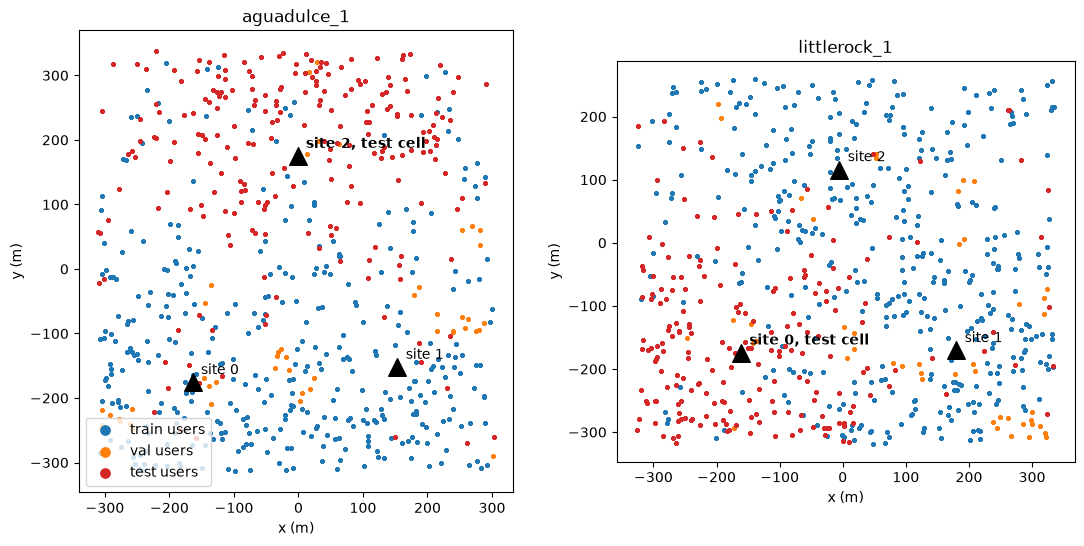

In [6]:
colors = {"train": "tab:blue", "val": "tab:orange", "test": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ci, (town, ax) in enumerate(zip(["aguadulce_1", "littlerock_1"], axes)):  # the order of the partition
    for s, color in colors.items():
        with np.load(WORK / "data" / f"{s}_labels.npz") as z:
            pos = z["rx_position"][z["city"] == ci]
        ax.scatter(pos[:, 0], pos[:, 1], s=5, c=color, label=f"{s} users")
    for site in range(3):
        with np.load(RUNS / town / f"channel_tx_{site * 6}.npz", allow_pickle=True) as z:
            x, y = np.ravel(z["metadata"].item()["tx_position"])[:2]
        held = site == split["held_out_site"][town]
        ax.scatter(x, y, marker="^", s=160, c="black", zorder=3)
        ax.annotate(f"site {site}" + (", test cell" if held else ""), (x, y), xytext=(6, 6),
                    textcoords="offset points", fontweight="bold" if held else "normal")
    ax.set(title=town, xlabel="x (m)", ylabel="y (m)", aspect="equal")
axes[0].legend(loc="lower left", markerscale=3)
plt.show()

Each set has its channels, [n, OFDM symbol, user antenna, base-station antenna, subcarrier], and one label array per field. `docs/data_format.md` describes every field.

In [7]:
h = np.load(WORK / "data" / "test.npy", mmap_mode="r")
with np.load(WORK / "data" / "test_labels.npz") as labels:
    fields = sorted(labels.files)
print("test channels", h.shape, h.dtype)
print("some label fields", fields[:8], "...")

test channels (2580, 14, 1, 32, 32) complex64
some label fields ['asa_rad', 'asd_rad', 'city', 'delay_spread_s', 'distance_m', 'dominant_doppler_hz', 'dominant_num_bounces', 'dominant_phi_r'] ...


## Step 2. Set up the config

The config names the data, the folders and the models. To keep this notebook fast, it probes only six quantities, instead of the full set of 24 quantities. It also uses the ridge probe and one MLP of 64 units with one seed, instead of the three MLP sizes with three seeds of the paper. The other keys take the defaults, which are the settings of the paper (see `configs/example.yaml`).

In [8]:
cfg = {
    "data_dir": str(WORK / "data"),
    "features_dir": str(WORK / "features"),
    "out_dir": str(WORK / "results"),
    "models": {
        "raw": {"raw": "complex"},            # raw baseline, real and imaginary parts of the first OFDM symbol
        "raw_logmag": {"raw": "logmag"},      # raw baseline, log10 |h|^2 of the first OFDM symbol
        "dummy": {"readouts": ["mean", "spatial"]},  # this is our dummy encoder
    },
    "quantities": ["distance", "path_gain", "delay_spread", "aod", "doppler", "speed"],
    "levels": {"mlp64": [64]},
    "seeds": [0],
}
(WORK / "my_eval.yaml").write_text(yaml.safe_dump(cfg, sort_keys=False))
cfg = load_config(WORK / "my_eval.yaml")

## Step 3. Write the features of a model

`encode` takes a batch of channels and returns one vector per channel for each readout. 

Here, we use a dummy encoder that projects the real and imaginary parts of each OFDM symbol and antenna pair with a fixed random matrix, so it gives one token per symbol and antenna pair. Its readout "mean" averages all tokens, and "spatial" averages the tokens of each base-station antenna and joins the results. 

For your own model, rewrite the body of `encode`, and put your model in evaluation mode.

`extract(encode, cfg, model)` does the following for the model of the config.

- It reads the channels of the train, val and test sets from `data_dir`, in batches of 512.
- With `snr_db`, it adds the same noise to each batch that the raw baselines get.
- It first checks that `encode` gives the same vector for the same channel, to catch a model in training mode.
- It calls `encode` on each batch and writes one feature file per readout and set to `<features_dir>/<model>/<readout>/<set>.npy`.

To use your own model, write `encode` in this form.

```python
model = load_my_model().eval().to("cuda")      # your model, in evaluation mode

def encode(h):                                 # h: [B, T, U, N, K] complex64 on the CPU
    x = my_preprocessing(h).to("cuda")         # scale, select and tokenize as your model expects
    tokens = model.encoder(x)                  # the representation to probe, for example [B, n_tokens, D]
    return {"mean": tokens.mean(1)}            # one [B, D] vector per readout of the config
```

ChaSE calls `encode` without gradients, so you do not need `torch.no_grad()`. Step 3 of the README gives every rule for `encode`, and `docs/data_format.md` gives the format of the channels.

In [9]:
# the same encoder as dummy_encoder in examples/extract_dummy.py, written out here to show its steps
proj = {}                                                         # one fixed random matrix per number of subcarriers


def encode(h):                                                    # h [B, T, U, N, K] complex64
    k = h.shape[-1]
    if k not in proj:
        proj[k] = torch.randn(2 * k, 16, generator=torch.Generator().manual_seed(0))   # 16 values per token
    x = torch.cat([h.real, h.imag], -1)                           # [B, T, U, N, 2K]
    x = x / x.flatten(1).std(1).clamp_min(1e-30).view(-1, 1, 1, 1, 1)
    z = x @ proj[k]                                               # tokens [B, T, U, N, 16]
    return {"mean": z.mean((1, 2, 3)), "spatial": z.mean((1, 2)).flatten(1)}


if not (features_path(cfg, "dummy", "spatial") / "test.npy").exists():
    extract(encode, cfg, "dummy")

dummy train: 4590 channels, readouts ['mean', 'spatial']


dummy val: 558 channels, readouts ['mean', 'spatial']


dummy test: 2580 channels, readouts ['mean', 'spatial']


## Step 4. Probe

`chase-run` trains and scores the probes of every model, readout and quantity of the config. It uses the GPU if PyTorch finds one. A run that stops resumes where it stopped.

In [10]:
# chase-run quickstart_work/my_eval.yaml
cli.run_main([str(WORK / "my_eval.yaml")])

coverage floor -150 dB keeps train 4584 of 4590, val 556 of 558, test 2568 of 2580 links


raw baselines: mean power 1.43004e-09 from the data_dir/manifest.yaml


raw/raw distance           linear -0.190 | best MLP 0.364


raw/raw path_gain          linear -0.110 | best MLP 0.665


raw/raw delay_spread       linear -0.034 | best MLP -0.095


raw/raw aod                linear -0.001 | best MLP 0.476


... (16 outputs left out)

dummy/spatial delay_spread       linear -0.015 | best MLP -0.119


dummy/spatial aod                linear -0.050 | best MLP 0.935


dummy/spatial doppler            linear -0.050 | best MLP -0.070


dummy/spatial speed              linear -0.021 | best MLP -0.026


## Step 5. Report

`chase-report` chooses the readout and the probe of each quantity on the validation links, and computes the shares and their 95% intervals.

In [11]:
# chase-report quickstart_work/my_eval.yaml
cli.report_main([str(WORK / "my_eval.yaml")])
display(Markdown((WORK / "results" / "report.md").read_text()))

quickstart_work/results/report.json


# ChaSE report (2026-11-02T00:24:28)

Each cell gives r_lin / r_best, the mean over the quantities of the group. The test R^2 is that of the choice on validation, with r_best at least r_lin.
Complete: True. Intervals from a bootstrap of 175 test tiles.

## Group means

| Model | link | delay | bs_angles | motion | user_angles |
|---|---|---|---|---|---|
| raw | - | - | - | - | - |
| raw_logmag | - | - | - | - | - |
| dummy | - | - | - | - | - |
| raw channel | - | - | - | - | - |

## Raw channel per quantity (baseline of r_best, chosen on validation)

distance raw (0.36), path_gain raw_logmag (0.95), delay_spread raw_logmag (-0.03), aod raw (0.48), doppler raw (-0.01), speed raw_logmag (-0.00)

## Lost share, max(0, r_best(raw) - r_best) [95% interval of r_best(raw) - r_best]

### link

| Model | distance | path_gain | k_factor | los_share | diffraction_share | specular_share | refraction_share | dominant_share | dominant_bounces |
|---|---|---|---|---|---|---|---|---|---|
| dummy | 0.00 [-0.66, -0.58] | 0.24 [0.19, 0.29] | - | - | - | - | - | - | - |

### delay

| Model | delay_spread | first_delay | excess_delay |
|---|---|---|---|
| dummy | 0.00 [0.00, 0.02] | - | - |

### bs_angles

| Model | aod | zod | asd | zsd |
|---|---|---|---|---|
| dummy | 0.00 [-0.49, -0.44] | - | - | - |

### motion

| Model | doppler | abs_doppler | max_doppler | speed |
|---|---|---|---|---|
| dummy | 0.00 [0.00, 0.00] | - | - | 0.00 [0.00, 0.00] |

### user_angles

| Model | aoa | zoa | asa | zsa |
|---|---|---|---|---|
| dummy | - | - | - | - |

## Shuffled-target controls (test R^2 of every fit)

| Probe | n | min | median | 95% | max |
|---|---|---|---|---|---|
| linear | 24 | -0.034 | -0.002 | 0.002 | 0.019 |
| mlp64 | 24 | -0.194 | -0.034 | 0.006 | 0.022 |


The report also has the numbers per quantity. For example, these are the shares of the dummy model. r_lin and r_best are the test R^2 values, which can be negative. The shares count a negative R^2 as 0, so a quantity that no probe reads is fully unread.

In [12]:
report = json.loads((WORK / "results" / "report.json").read_text())
print(f"{'quantity':14s} {'r_lin':>6s} {'r_best':>6s} {'available':>9s} {'entangled':>9s} {'unread':>6s} {'lost':>5s}")
for q, c in report["models"]["dummy"]["quantities"].items():
    lost = report["models"]["dummy"]["lost"][q]["lost"]
    print(f"{q:14s} {c['r_lin']:6.2f} {c['r_best']:6.2f} {c['available']:9.2f} {c['entangled']:9.2f} "
          f"{c['unread']:6.2f} {lost:5.2f}")

quantity        r_lin r_best available entangled unread  lost
distance        -0.01   0.98      0.00      0.98   0.02  0.00
path_gain       -0.00   0.71      0.00      0.71   0.29  0.24
delay_spread    -0.01  -0.01      0.00      0.00   1.00  0.00
aod             -0.00   0.93      0.00      0.93   0.07  0.00
doppler         -0.01  -0.01      0.00      0.00   1.00  0.00
speed           -0.02  -0.02      0.00      0.00   1.00  0.00


## Next steps

- Replace the dummy `encode` with your model, and add its readouts to the config.
- Probe all 24 quantities with the probes of the paper, with the defaults of `configs/example.yaml`.
- Use the full urban, suburban and rural cells of the paper (the section "Demonstration in the paper" of the README), or your own data (`docs/data_format.md`).